<a href="https://colab.research.google.com/github/RMwiggins718/Convolutional-Neural-Network-CNN-for-MNIST-Handwritten-Digit-Classification/blob/main/minst_RWiggins.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MINST Handwritten Digit Classification with CNN

This notebook implements, trains, and evaluates a Convolutional Nueral Network (CNN) in Pytorch to classify handwritten digits from the MINST dataset.

In [10]:
# Cell 1: Dependencies & Device Setup

import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Hyperparameters & Device Configuration
BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 12
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {DEVICE}")

Using device: cpu


## 1. Data Preprocessing and Loaders

Here we load the MNIST dataset, apply standard normalization, and split the training set into training (90%) and validation (10%) subsets.

In [11]:
# Cell 2: Data Preprocessing & DataLoaders

# Image normalization transform (MNIST mean=0.1307, std=0.3081)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

# Download and load full training + test datasets
full_train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

# Stratified 90/10 Train/Validation Split
train_size = int(0.9 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(
    full_train_dataset, [train_size, val_size]
)

# Optimized DataLoaders with pinned memory support
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True
)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Testing samples: {len(test_dataset)}")

Training samples: 54000
Validation samples: 6000
Testing samples: 10000


## 2. CNN Architecture Definition

The network features two convolutional blocks (with pooling and dropout) followed by a fully connected classification head.

In [12]:
# Cell 3: CNN Model Definition

class DigitCNN(nn.Module):

  def __init__(self):
    super(DigitCNN, self).__init__()

    # Conv Block 1: Input (1x28x28) -> Output (32x14x14)
    self.conv_block1 = nn.Sequential(
        nn.Conv2d(
            in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )

    # Conv Block 2: Input (32x14x14) -> Output (64x7x7)
    self.conv_block2 = nn.Sequential(
        nn.Conv2d(
            in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
        nn.Dropout2d(p=0.25),
    )

    # Fully Connected Head
    self.fc_head = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64 * 7 * 7, 128),
        nn.ReLU(),
        nn.Dropout(p=0.5),
        nn.Linear(128, 10),
    )

  def forward(self, x):
    x = self.conv_block1(x)
    x = self.conv_block2(x)
    x = self.fc_head(x)
    return x


# Instantiate model and print architecture
model = DigitCNN().to(DEVICE)
print(model)

DigitCNN(
  (conv_block1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout2d(p=0.25, inplace=False)
  )
  (fc_head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 3. Model Training & Validation Loop

Optimized training loop utilizing torch.inference_mode and gradient clearing adjustments for rapid epoch execution.

In [13]:
# Cell 4: Model Training & Validation

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
}

print(f"Starting training for {EPOCHS} epochs...")
start_time = time.time()

for epoch in range(EPOCHS):
  # --- Training Phase ---
  model.train()
  running_loss, correct, total = 0.0, 0, 0

  for images, labels in train_loader:
    images, labels = images.to(DEVICE, non_blocking=True), labels.to(
        DEVICE, non_blocking=True
    )

    optimizer.zero_grad(set_to_none=True)
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * images.size(0)
    correct += (outputs.argmax(dim=1) == labels).sum().item()
    total += labels.size(0)

  train_loss, train_acc = running_loss / total, correct / total

  # --- Validation Phase ---
  model.eval()
  val_loss, val_correct, val_total = 0.0, 0, 0

  with torch.inference_mode():
    for images, labels in val_loader:
      images, labels = images.to(DEVICE, non_blocking=True), labels.to(
          DEVICE, non_blocking=True
      )
      outputs = model(images)
      loss = criterion(outputs, labels)

      val_loss += loss.item() * images.size(0)
      val_correct += (outputs.argmax(dim=1) == labels).sum().item()
      val_total += labels.size(0)

  val_loss, val_acc = val_loss / val_total, val_correct / val_total

  # Store history
  history['train_loss'].append(train_loss)
  history['train_acc'].append(train_acc)
  history['val_loss'].append(val_loss)
  history['val_acc'].append(val_acc)

  print(
      f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
      f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | "
      f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%"
  )

print(f"Training completed in {time.time() - start_time:.2f} seconds.")

Starting training for 12 epochs...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [01/12] | Train Loss: 0.2515 | Train Acc: 92.15% | Val Loss: 0.0645 | Val Acc: 98.23%
Epoch [02/12] | Train Loss: 0.0959 | Train Acc: 97.12% | Val Loss: 0.0463 | Val Acc: 98.70%
Epoch [03/12] | Train Loss: 0.0744 | Train Acc: 97.75% | Val Loss: 0.0412 | Val Acc: 98.80%
Epoch [04/12] | Train Loss: 0.0646 | Train Acc: 98.10% | Val Loss: 0.0418 | Val Acc: 98.82%
Epoch [05/12] | Train Loss: 0.0574 | Train Acc: 98.27% | Val Loss: 0.0380 | Val Acc: 98.83%
Epoch [06/12] | Train Loss: 0.0515 | Train Acc: 98.43% | Val Loss: 0.0370 | Val Acc: 98.80%
Epoch [07/12] | Train Loss: 0.0492 | Train Acc: 98.46% | Val Loss: 0.0328 | Val Acc: 98.90%
Epoch [08/12] | Train Loss: 0.0452 | Train Acc: 98.66% | Val Loss: 0.0325 | Val Acc: 98.92%
Epoch [09/12] | Train Loss: 0.0417 | Train Acc: 98.70% | Val Loss: 0.0343 | Val Acc: 99.00%
Epoch [10/12] | Train Loss: 0.0398 | Train Acc: 98.77% | Val Loss: 0.0281 | Val Acc: 99.17%
Epoch [11/12] | Train Loss: 0.0376 | Train Acc: 98.81% | Val Loss: 0.0319 | Val 

## 4. Test Set Evaluation

Evaluating generalizability on the held-out test dataset.

In [14]:
# Cell 5: Test Set Evaluation

model.eval()
test_correct, test_total = 0, 0

with torch.inference_mode():
  for images, labels in test_loader:
    images, labels = images.to(DEVICE, non_blocking=True), labels.to(
        DEVICE, non_blocking=True
    )
    outputs = model(images)
    _, predicted = outputs.max(1)

    test_total += labels.size(0)
    test_correct += predicted.eq(labels).sum().item()

final_test_acc = (test_correct / test_total) * 100
print(
    f"Final Test Accuracy on unseen data ({test_total} images):"
    f" {final_test_acc:.2f}%"
)

Final Test Accuracy on unseen data (10000 images): 99.20%


## 5. Visualizing Training Dynamics & Internal Feature Representations

Plotting loss/accuracy curves alongside first-layer filter weights and block feature maps.

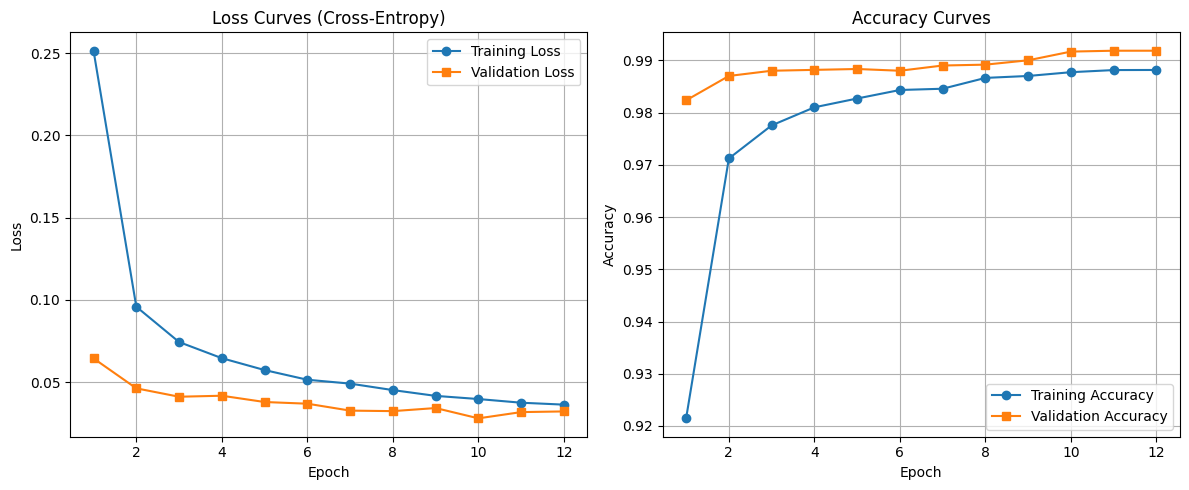

In [15]:
# Cell 6 : Visualizing Training & Loss Curves

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(
    epochs_range, history["train_loss"], label="Training Loss", marker="o"
)
plt.plot(
    epochs_range, history["val_loss"], label="Validation Loss", marker="s"
)
plt.title("Loss Curves (Cross-Entropy)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

# Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(
    epochs_range, history["train_acc"], label="Training Accuracy", marker="o"
)
plt.plot(
    epochs_range, history["val_acc"], label="Validation Accuracy", marker="s"
)
plt.title("Accuracy Curves")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

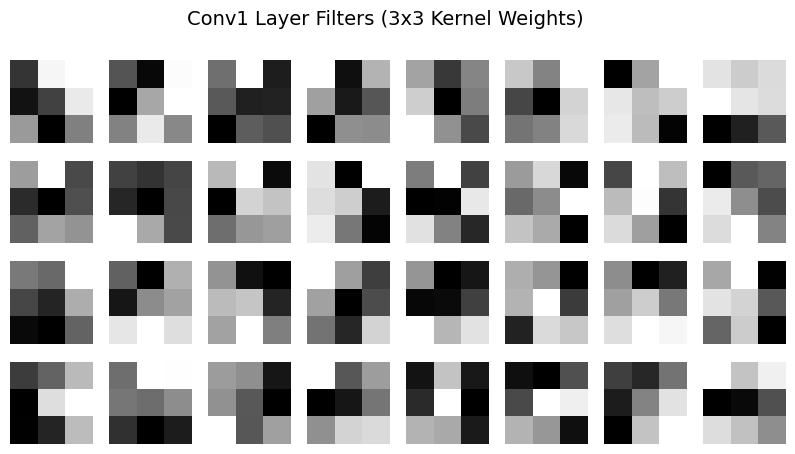

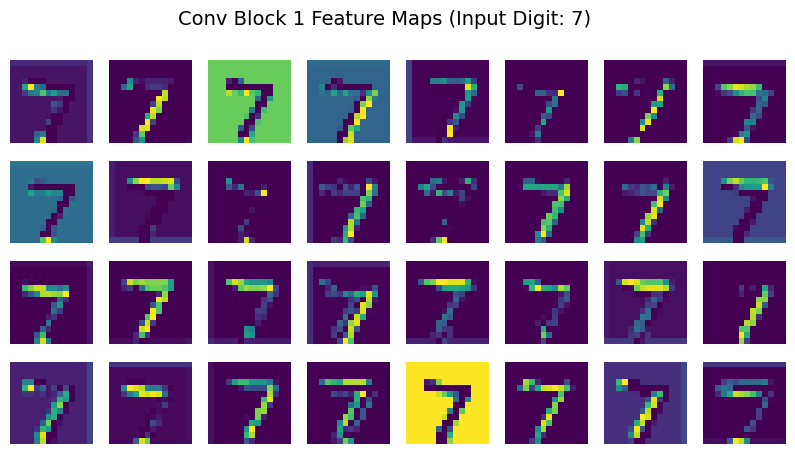

In [16]:
# Cell 7: Visualizing Conv Layer Filters & Feature Maps

# 1. Visualize Conv1 Filters (32 kernels of shape 3x3)
conv1_weights = model.conv_block1[0].weight.data.cpu()

plt.figure(figsize=(10, 5))
for i in range(32):
  plt.subplot(4, 8, i + 1)
  plt.imshow(conv1_weights[i, 0], cmap="gray")
  plt.axis("off")
plt.suptitle("Conv1 Layer Filters (3x3 Kernel Weights)", fontsize=14)
plt.show()

# 2. Extract and Visualize Feature Maps for a sample digit
sample_img, sample_label = test_dataset[0]
sample_tensor = sample_img.unsqueeze(0).to(DEVICE)

with torch.inference_mode():
  feature_maps_b1 = model.conv_block1(sample_tensor).cpu().squeeze(0)

plt.figure(figsize=(10, 5))
for i in range(32):
  plt.subplot(4, 8, i + 1)
  plt.imshow(feature_maps_b1[i], cmap="viridis")
  plt.axis("off")
plt.suptitle(
    f"Conv Block 1 Feature Maps (Input Digit: {sample_label})", fontsize=14
)
plt.show()
